# **Capitolo 3. Analisi ed Elaborazione dell'Offerta Second-Hand**

L'obiettivo del presente notebook è ridurre le categorie di appartenza dei prodotti a un **numero ridotto**. La struttura delle precedenti categorie, per quanto sia completa, si rivela al contempo troppo frammentata. Le categorie uniche presenti sono 147, un numero inferiore rispetto alle 215 ufficiali, ma ancora elevato per consentire una lettura chiara dei differenti segmenti di articoli. La loro distribuzione è sbilanciata: poche categorie assorbono una quota rilevante di articoli, mentre una lunga coda di categorie residuali contiene poche occorrenze.

> Questo terzo e ultimo notebook riguardante le procedure descritte nel terzo capitolo, si occupa della riduzione a macro-categorie omogenee (*l'intero paragrafo 3.5 con annesse sottosezioni, quindi fino alla fine del capitolo*). 

## **3.5. Riduzione a macro-categorie omogenee**

Si importano preliminarmente le librerie necessarie e si carica il dataset prodotto dal notebook precedente, cioè `2_categorie__usato.ipynb`.

In [ ]:
import os
import json
from pathlib import Path
import pandas as pd
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import seaborn as sns
import sys
import graphviz
from IPython.display import display, Image, HTML, clear_output
import re
import subprocess
from google import genai
import google.generativeai as genai 
import anthropic
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
import warnings
warnings.filterwarnings("ignore")
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import ipywidgets as widgets
import plotly.express as px
from matplotlib.patches import FancyBboxPatch

# Allineamento directory e lettura dati
while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")

cartella_risultati_usato = Path("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
file_csv = cartella_risultati_usato / "2_categorie__usato.csv"

df = pd.read_csv(file_csv, dtype={'Numero Articolo Catalogo': str, 'ID Prodotto': str},)
print(f"File Identificato: {file_csv.name}.")
print(f"Dimensioni dataset originale: {df.shape}.\n")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

Analizziamo preliminarmente le categorie esistenti.

In [4]:
col_categoria = 'Categoria Principale'

# Contiamo i valori mancanti e i valori presenti
valori_mancanti = df[col_categoria].isnull().sum()
valori_presenti = df[col_categoria].notnull().sum()

print(f"Totale righe nel dataset: {len(df)}.")
print(f"Articoli con categoria assegnata: {valori_presenti}.")
print(f"Articoli senza categoria (valori nulli): {valori_mancanti}.")

# Controllo di coerenza
if valori_presenti == len(df):
    print("\nControllo superato: il numero degli articoli con categoria coincide perfettamente con il totale delle righe del dataset.")
else:
    print("\nAttenzione: ci sono articoli senza categoria.")

Totale righe nel dataset: 9405.
Articoli con categoria assegnata: 9405.
Articoli senza categoria (valori nulli): 0.

Controllo superato: il numero degli articoli con categoria coincide perfettamente con il totale delle righe del dataset.


In [5]:
# Calcoliamo il numero di categorie univoche e delle frequenze assolute
num_categorie_univoche = df[col_categoria].nunique()
print(f"\nEsistono {num_categorie_univoche} categorie principali univoche.")
frequenze_assolute = df[col_categoria].value_counts()

# Calcolo delle percentuali esatte
frequenze_percentuali = df[col_categoria].value_counts(normalize=True) * 100

df_frequenze = pd.DataFrame({'Conteggio': frequenze_assolute, 'Percentuale (%)': frequenze_percentuali})
print("\nTop 20 categorie più frequenti:")
print(df_frequenze.head(20)) # Mostra le prime 20 categorie


Esistono 147 categorie principali univoche.

Top 20 categorie più frequenti:
                                             Conteggio  Percentuale (%)
Categoria Principale                                                   
Fodere per divani e poltrone                      1027        10.919724
Cucine componibili e modulari                      975        10.366826
Sistemi componibili per organizzare la casa        638         6.783626
Lampade e lampadari                                620         6.592238
Tende a rullo                                      308         3.274854
METOD ripiani e cassetti per cucine                250         2.658161
Bambini, arredamento e accessori                   247         2.626263
Illuminazione per mobili                           241         2.562467
Tessile da letto                                   215         2.286018
Illuminazione e accessori smart home               194         2.062733
Specchi                                            189    

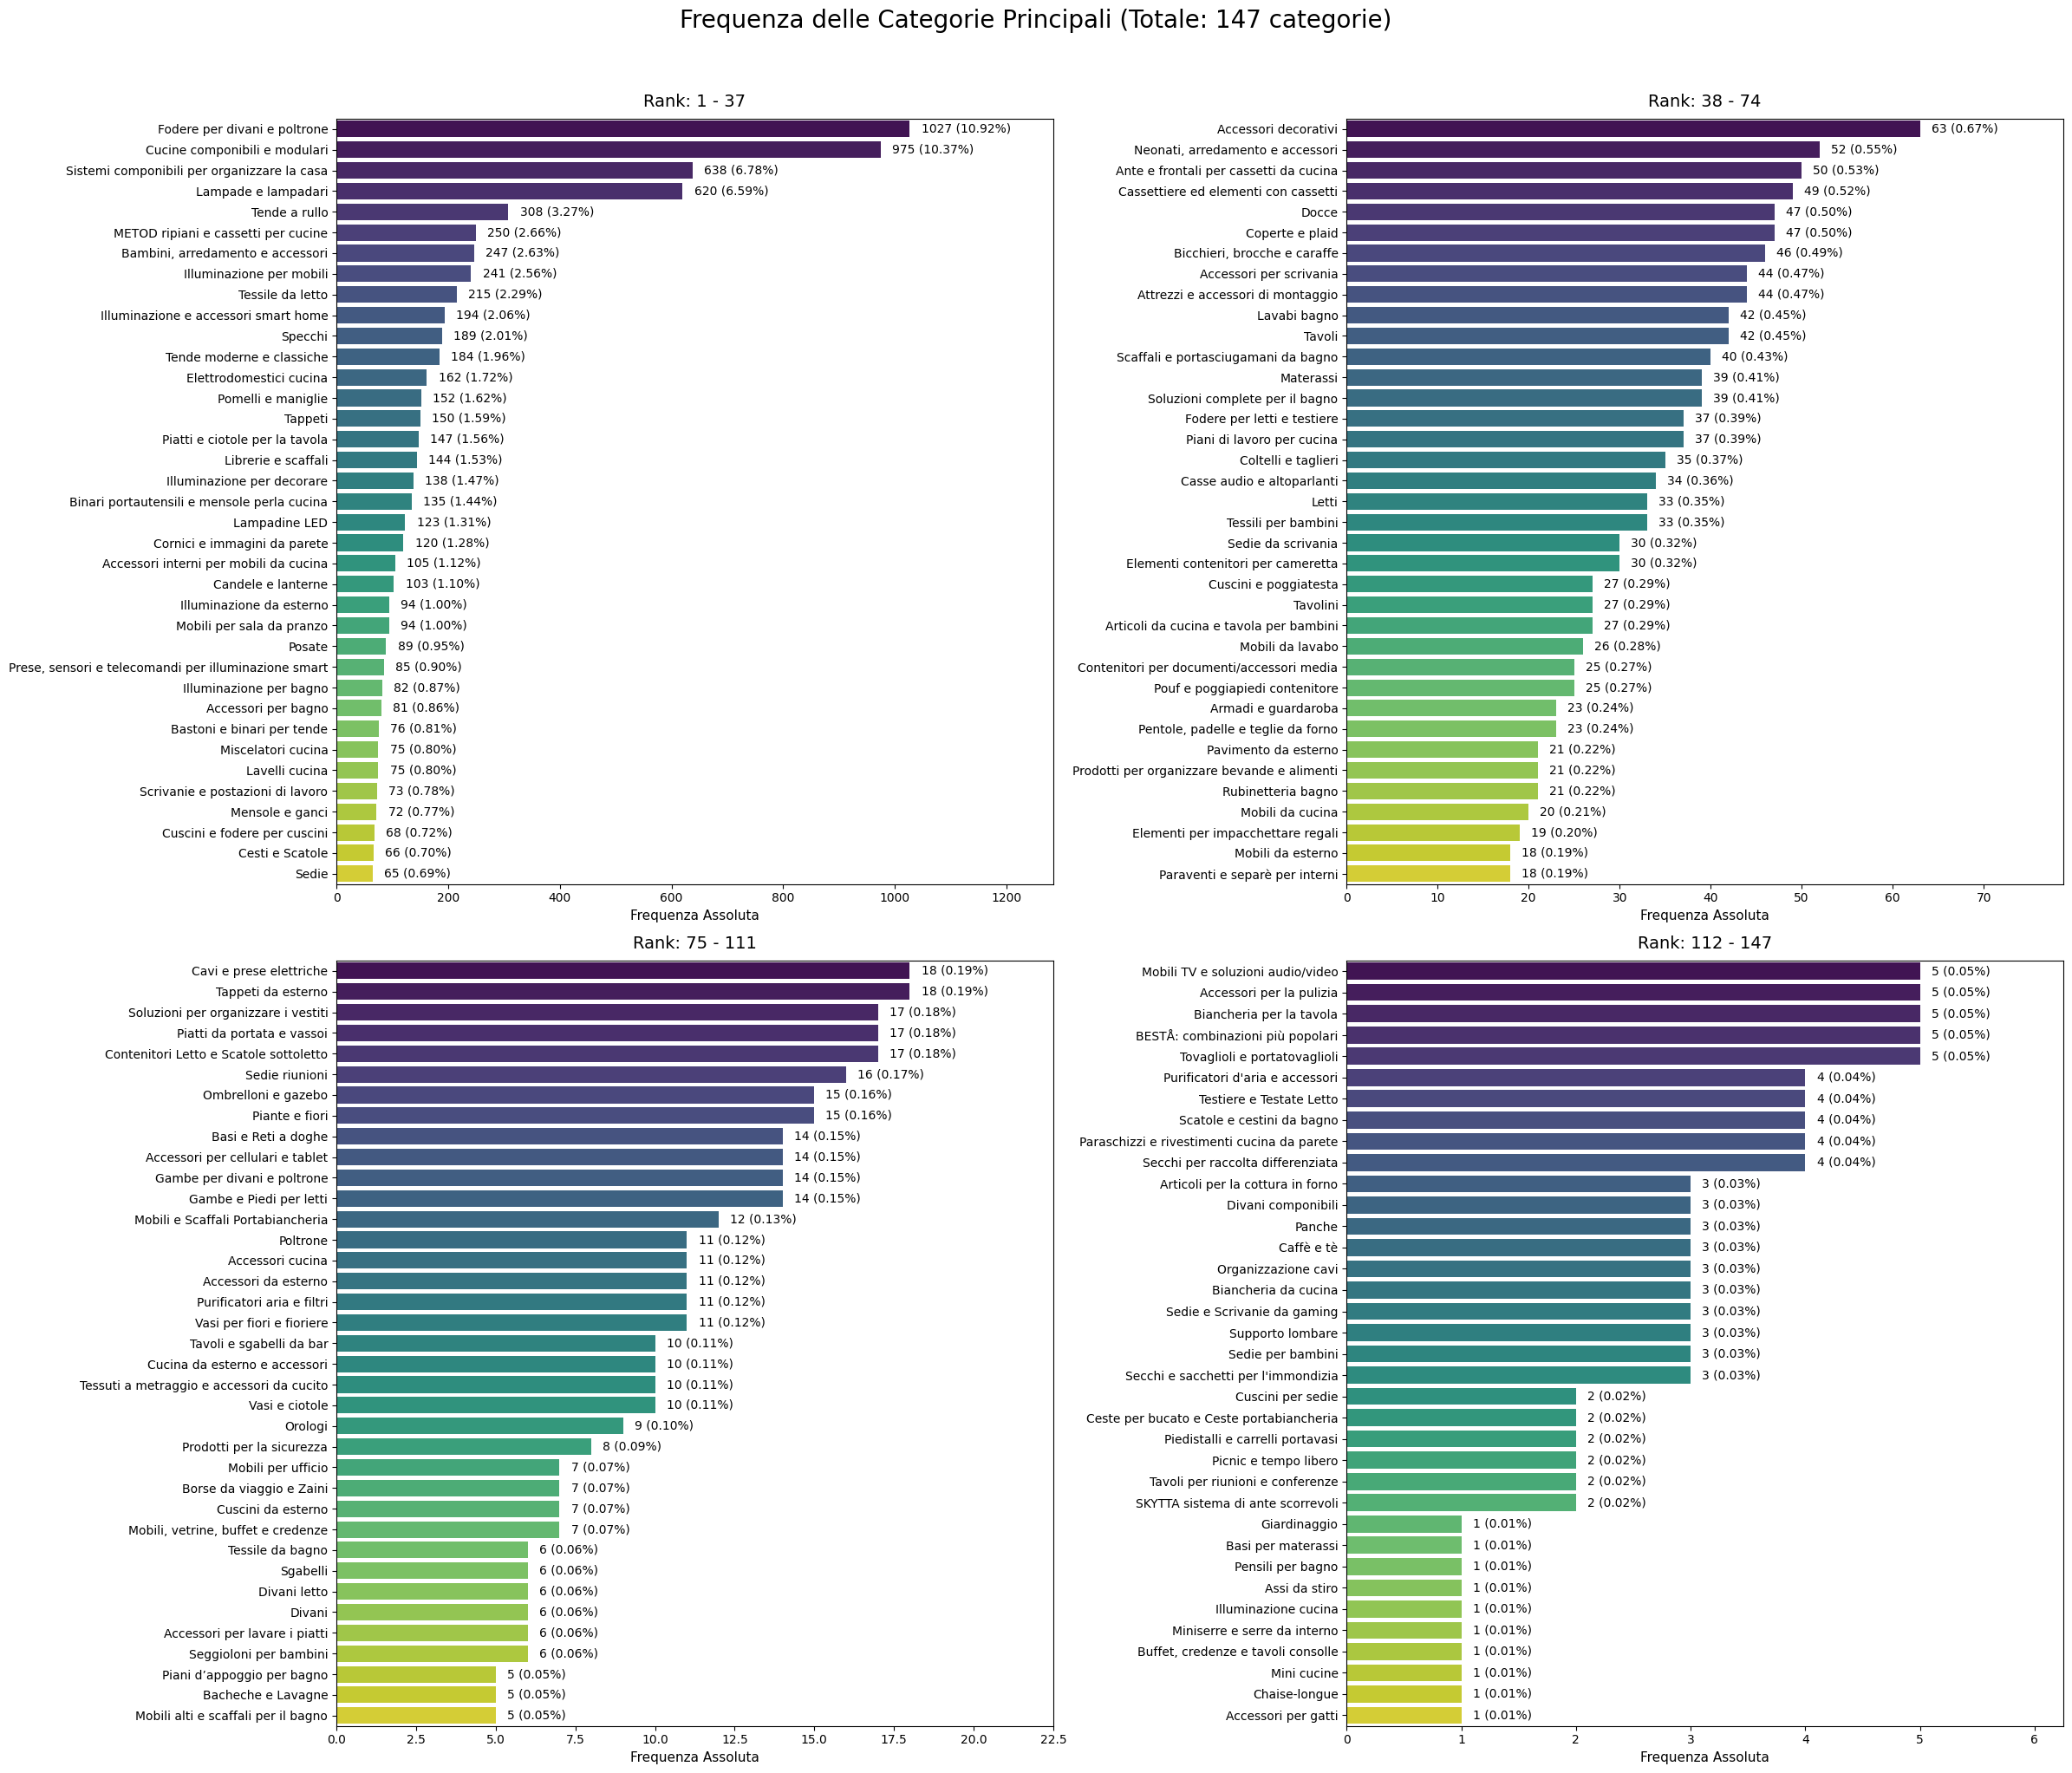

In [6]:
frequenze_assolute = df[col_categoria].value_counts()
frequenze_percentuali = df[col_categoria].value_counts(normalize=True) * 100
tot_cat = len(frequenze_assolute)

# Dividiamo le categorie in 4 gruppi in modo equo (circa 37 categorie per grafico)
chunk_size = math.ceil(tot_cat / 4)

# Creiamo una griglia 2x2 (4 pannelli) molto grande per favorire la lettura
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(24, 20))
axes = axes.flatten() # Appiattiamo l'array di assi per poterci iterare facilmente

# Cicliamo sui 4 pannelli
for i in range(4):
    # Calcoliamo gli indici di inizio e fine per il gruppo corrente
    start_idx = i * chunk_size
    end_idx = min((i + 1) * chunk_size, tot_cat)
    
    # Se per caso abbiamo finito le categorie, interrompiamo il ciclo
    if start_idx >= tot_cat:
        axes[i].set_visible(False)
        continue
        
    # Estraiamo i dati specifici per il pannello corrente
    chunk_assolute = frequenze_assolute.iloc[start_idx:end_idx]
    chunk_percentuali = frequenze_percentuali.iloc[start_idx:end_idx]
    
    # Creiamo il grafico a barre orizzontali
    sns.barplot(x=chunk_assolute.values, y=chunk_assolute.index, hue=chunk_assolute.index, legend=False, ax=axes[i], palette='viridis')
    
    # Titoli e personalizzazioni per il singolo pannello
    axes[i].set_title(f'Rank: {start_idx + 1} - {end_idx}', fontsize=14, pad=10)
    axes[i].set_xlabel('Frequenza Assoluta', fontsize=11)
    axes[i].set_ylabel('') 
    
    # Aggiungiamo i numeri (conteggio e percentuale esatta con 2 decimali) alla fine di ogni barra
    for index, value in enumerate(chunk_assolute.values):
        perc = chunk_percentuali.iloc[index]
        axes[i].text(value + (max(chunk_assolute.values) * 0.02), index, f'{value} ({perc:.2f}%)', va='center', fontsize=10)
        
    # Aggiungiamo un po' di margine a destra nel singolo grafico per non far tagliare il testo
    axes[i].set_xlim(0, max(chunk_assolute.values) * 1.25)

plt.suptitle(f'Frequenza delle Categorie Principali (Totale: {tot_cat} categorie)', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

In [7]:
somma_totale_categorie = frequenze_assolute.sum()
righe_valide = df[col_categoria].count()
print(f"Somma degli articoli in tutte le 147 categorie: {somma_totale_categorie}.")
print(f"Totale righe non nulle nella colonna originale: {righe_valide}.")

if somma_totale_categorie == righe_valide:
    print("\nIl controllo con le righe è andato a buon fine: la somma è uguale al numero di righe valide.")
else:
    print("\nAttenzione: c'è una discrepanza tra la somma delle categorie e le righe valide.")

Somma degli articoli in tutte le 147 categorie: 9405.
Totale righe non nulle nella colonna originale: 9405.

Il controllo con le righe è andato a buon fine: la somma è uguale al numero di righe valide.


### **3.5.1. Limiti e granularità del catalogo ufficiale**

Prima di utilizzare la tassonomia estratta come base per le successive attività di classificazione e recupero delle categorie mancanti, è stata effettuata una verifica della sua coerenza strutturale. L'obiettivo dell'analisi è individuare **eventuali anomalie nella gerarchia delle categorie** presenti sul sito dell'azienda. In una struttura tassonomica ideale, ogni nodo dovrebbe appartenere ad un solo livello gerarchico e dovrebbe essere raggiungibile attraverso un unico percorso. Tuttavia, nelle architetture informative reali, soprattutto nei cataloghi e-commerce di grandi dimensioni, possono verificarsi situazioni in cui la stessa categoria viene riutilizzata in più contesti oppure compare contemporaneamente a livelli diversi della gerarchia.

Per effettuare questa verifica è stato utilizzato il file `categorie_complete.json`, ottenuto durante la fase di estrazione delle categorie di terzo livello (nel notebook precedente) e arricchito con le specifiche delle categorie di primo livello. Tale file rappresenta la struttura tassonomica come un insieme di relazioni tra:

* Livello 1 (macro-categorie);
* Livello 2 (categorie);
* Livello 3 (sottocategorie).

La procedura ha trasformato la tassonomia in un insieme di nodi e archi orientati, costruendo un **grafo che rappresenta tutte le relazioni padre-figlio presenti nel catalogo**. Successivamente è stata eseguita un'analisi dei percorsi in entrata verso ciascun nodo. Un nodo viene considerato anomalo quando possiede più di un genitore, ovvero quando può essere raggiunto tramite percorsi differenti. Le **anomalie** individuate sono state suddivise in tre categorie principali: i `salti di livello’ (cross-level), quando uno stesso nodo compare sia come categoria di secondo livello sia come sottocategoria di terzo livello; le `categorie condivise' (shared level 2), quando un nodo compare come categoria di secondo livello ma presenta più macro-categorie come genitori diretti; infine, le `sottocategorie condivise’ (shared level 3), quando un nodo compare sempre come sottocategoria di terzo livello ma presenta più categorie di secondo livello come genitori diretti.

Per facilitare l'interpretazione dei risultati è stato costruito un **grafo orientato** utilizzando la libreria `Graphviz`. La visualizzazione mostra **esclusivamente i percorsi coinvolti nelle anomalie individuate**, eliminando tutti i rami regolari della tassonomia e concentrando l'attenzione sulle sole aree problematiche. I nodi sono stati colorati in funzione della tipologia di anomalia rilevata: azzurro, nodi regolari utilizzati come contesto per la lettura del grafo; arancione, categorie coinvolte in salti di livello (cross-level); viola, categorie di secondo livello condivise tra più macro-categorie; rosso, sottocategorie condivise tra più categorie di livello superiore.

In [ ]:
# Caricamento dei dati
cartella_base = Path("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
cartelle_estrazione = sorted(cartella_base.glob("Estrazione Categorie__*"), reverse=True)

if cartelle_estrazione:
    cartella_piu_recente = cartelle_estrazione[0]
    percorso_file = cartella_piu_recente / "categorie_complete.json"
    print(f"Trovata la cartella: {cartella_piu_recente.name}")
else:
    print(f"Errore: Nessuna cartella trovata in {cartella_base}")
    sys.exit()

try:
    with open(percorso_file, 'r', encoding='utf-8') as f:
        data = json.load(f)
except FileNotFoundError:
    print(f"Errore: Il file {percorso_file.name} non esiste nel percorso.")
    sys.exit()

# Analisi dei livelli e dei percorsi
l2_nodes = set()
l3_nodes = set()
edges = []

# Raccogliamo tutti gli archi (L1->L2 e L2->L3) e teniamo traccia dei livelli
for l1, l2_dict in data.items():
    for l2, l3_list in l2_dict.items():
        l2_nodes.add(l2)
        edges.append((l1, l2))
        for l3 in l3_list:
            l3_nodes.add(l3)
            edges.append((l2, l3))

# Mappiamo i genitori di ciascun nodo per trovare le anomalie
parents_of = {}
for p, c in edges:
    if c not in parents_of:
        parents_of[c] = set()
    parents_of[c].add(p)

# Isoliamo tutti i nodi con più di un percorso in entrata
ambiguous_nodes = {n for n, p in parents_of.items() if len(p) > 1}

# Classificazione delle anomalie
cross_level = ambiguous_nodes.intersection(l2_nodes).intersection(l3_nodes)
shared_l2 = ambiguous_nodes.intersection(l2_nodes) - cross_level
shared_l3 = ambiguous_nodes.intersection(l3_nodes) - cross_level

print("\nAnomalie individuate")
print(f"-> Totale nodi con percorsi multipli: {len(ambiguous_nodes)}.")
print(f"-> Salti di Livello (L2/L3): {len(cross_level)}.")
print(f"-> Categorie contese (L2): {len(shared_l2)}.")
print(f"-> Sottocategorie contese (L3): {len(shared_l3)}.\n")

# Creazione del grafo
dot = graphviz.Digraph(comment='Anomalie Strutturali', engine='dot')
dot.attr(rankdir='LR', nodesep='0.35', ranksep='1.2', bgcolor='white', splines='true')
dot.attr('node', fontname='Helvetica', fontsize='10', shape='box', style='rounded, filled', margin='0.15,0.1')
dot.attr('edge', color='#999999', arrowsize='0.6')

nodes_to_draw = set()
edges_to_draw = set()

# Filtriamo per disegnare solo i percorsi che portano a un nodo anomalo
for p, c in edges:
    if c in ambiguous_nodes:
        edges_to_draw.add((p, c))
        nodes_to_draw.update([p, c])

# Assegnazione dei colori a seconda dell'anomalia individuata
for node in nodes_to_draw:
    if node in cross_level:
        # Arancione: L'anomalia principale (è sia L2 che L3)
        dot.node(node, node, fillcolor='#ffe0b2', color='#f57c00', penwidth='1.5')
    elif node in shared_l2:
        # Viola: L2 Condivisa
        dot.node(node, node, fillcolor='#e1bee7', color='#8e24aa', penwidth='1.5')
    elif node in shared_l3:
        # Rosso: L3 Condiviso
        dot.node(node, node, fillcolor='#ffcdd2', color='#d32f2f', penwidth='1.5')
    else:
        # Azzurro: Nodo Genitore standard
        dot.node(node, node, fillcolor='#e3f2fd', color='#1976d2', penwidth='1.2')

for p, c in edges_to_draw:
    dot.edge(p, c)

# Esportazione in PDF e anteprima immagine compressa per VSCode
nome_file_output = cartella_piu_recente / 'anomalie_struttura_categorie'

dot.graph_attr['dpi'] = '300'
dot.render(str(nome_file_output), format='pdf', view=False, cleanup=True)

dot.graph_attr['dpi'] = '100'
percorso_preview = dot.render(str(nome_file_output), format='png', view=False, cleanup=True)

print(f"File vettoriale salvato: {nome_file_output}.pdf")
display(Image(filename=percorso_preview, width=1100))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# Costruzione percorsi: tutte le strade che portano ai nodi
percorsi_verso = {}
l2_nodes, l3_nodes = set(), set()

for l1, l2_dict in data.items():

    for l2, l3_list in l2_dict.items():
        l2_nodes.add(l2)
        percorsi_verso.setdefault(l2, []).append([l1, l2])

        for l3 in l3_list:
            l3_nodes.add(l3)
            percorsi_verso.setdefault(l3, []).append([l1, l2, l3])

# Identificazione anomalie
nodi_anomali = {nodo: percorsi for nodo, percorsi in percorsi_verso.items() if len(percorsi) > 1}
nodi = set(nodi_anomali)
cross_level = nodi & l2_nodes & l3_nodes
shared_l2 = (nodi & l2_nodes) - cross_level
shared_l3 = (nodi & l3_nodes) - cross_level

# Cartella output
cartella_output = cartella_piu_recente / "singole_anomalie_struttura_categorie"
cartella_output.mkdir(exist_ok=True)
display(HTML(f"<h3 style='color:#2E86AB;'> Trovate {len(nodi_anomali)} anomalie. Generazione in corso...</h3><hr>"))

# Funzione colore per lo stile del nodo
def stile_nodo(nodo, target):
    if nodo != target:
        return dict(fillcolor='#e3f2fd', color='#1976d2', penwidth='1')
    if nodo in cross_level:
        return dict(fillcolor='#ffe0b2', color='#f57c00', penwidth='1.5')
    if nodo in shared_l2:
        return dict(fillcolor='#e1bee7', color='#8e24aa', penwidth='1.5')
    return dict(fillcolor='#ffcdd2', color='#d32f2f', penwidth='1.5')

# Generazione dei mini grafi
for nodo_target, percorsi in nodi_anomali.items():
    nome = re.sub(r'_+', '_', re.sub(r'[^A-Za-z0-9]', '_', nodo_target)).strip('_')
    dot = graphviz.Digraph()
    dot.attr(rankdir='LR',nodesep='0.3',ranksep='0.8')
    dot.attr('node',shape='box',style='rounded,filled',fontsize='10')
    visitati = set()

    for percorso in percorsi:
        for i, nodo in enumerate(percorso):
            if nodo not in visitati:
                dot.node(nodo,nodo,**stile_nodo(nodo, nodo_target))
                visitati.add(nodo)
            if i:
                dot.edge(percorso[i-1], nodo)
    try:
        file_pdf = cartella_output / f"Anomalia_{nome}"
        pdf = subprocess.run(["dot", "-Tpdf"],input=dot.source.encode(),capture_output=True,check=True)
        with open(f"{file_pdf}.pdf", "wb") as f:
            f.write(pdf.stdout)  
        png = subprocess.run(["dot", "-Tpng"],input=dot.source.encode(),capture_output=True,check=True)
        display(HTML(f"<b>{nodo_target}</b>"))
        display(Image(data=png.stdout))
    except subprocess.CalledProcessError:
        print(f"Errore → {nodo_target}")

display(HTML(f"<hr><h3 style='color:green;'> PDF salvati in:<br><code>{cartella_output}</code> </h3>"))


### Qualche esempio è presente nella stesura della tesi.
### [Output rimosso per tutela della privacy e riservatezza commerciale]

### **3.5.2. Dagli approcci automatici alla classificazione finale interattiva**

Con la struttura ora analizzata, si procede alla **riduzione vera e propria** delle categorie originali in un insieme compatto di macro-categorie. Si esplorano più approcci in sequenza, ciascuno motivato dai limiti di quello precedente.

-> **Approccio 1: clustering semantico basato su embedding vettoriali**

L'idea di fondo è trasformare ogni etichetta di categoria in un vettore numerico che ne catturi il significato, per poi raggruppare i vettori simili tramite un algoritmo di clustering. Il processo si articola in quattro fasi: embedding; ricerca del K ottimale; clustering finale; ispezione manuale.

In [10]:
# Configurazione
K_MIN = 20
K_MAX = 35
K_FINALE = 24   # Da aggiornare anche dopo aver visto il grafico Elbow/Silhouette
MODELLO_EMBEDDING = "paraphrase-multilingual-MiniLM-L12-v2"
RANDOM_STATE = 42

In [11]:
# Embedding
categorie = frequenze_assolute.index.tolist()
print(f"Categorie da embeddare: {len(categorie)}.")

model_emb = SentenceTransformer(MODELLO_EMBEDDING)
print(f"Modello caricato: {MODELLO_EMBEDDING}.")

embeddings = model_emb.encode(categorie, show_progress_bar=True, batch_size=64)

# Normalizzazione L2: rende la distanza euclidea equivalente alla cosine distance
embeddings = normalize(embeddings, norm="l2")
print(f"Shape embedding: {embeddings.shape}.")

Categorie da embeddare: 147.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modello caricato: paraphrase-multilingual-MiniLM-L12-v2.


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Shape embedding: (147, 384).


Test K-Means per K da 20 a 35...

  K=20 | Inertia=    48.8 | Silhouette=0.1057
  K=21 | Inertia=    47.8 | Silhouette=0.1070
  K=22 | Inertia=    47.0 | Silhouette=0.1102
  K=23 | Inertia=    45.9 | Silhouette=0.1204
  K=24 | Inertia=    45.6 | Silhouette=0.1248
  K=25 | Inertia=    44.9 | Silhouette=0.0989
  K=26 | Inertia=    43.9 | Silhouette=0.1135
  K=27 | Inertia=    43.1 | Silhouette=0.1173
  K=28 | Inertia=    42.3 | Silhouette=0.1110
  K=29 | Inertia=    41.4 | Silhouette=0.0969
  K=30 | Inertia=    40.7 | Silhouette=0.1074
  K=31 | Inertia=    40.1 | Silhouette=0.1012
  K=32 | Inertia=    38.9 | Silhouette=0.1287
  K=33 | Inertia=    38.1 | Silhouette=0.1184
  K=34 | Inertia=    37.7 | Silhouette=0.1333
  K=35 | Inertia=    36.8 | Silhouette=0.1225


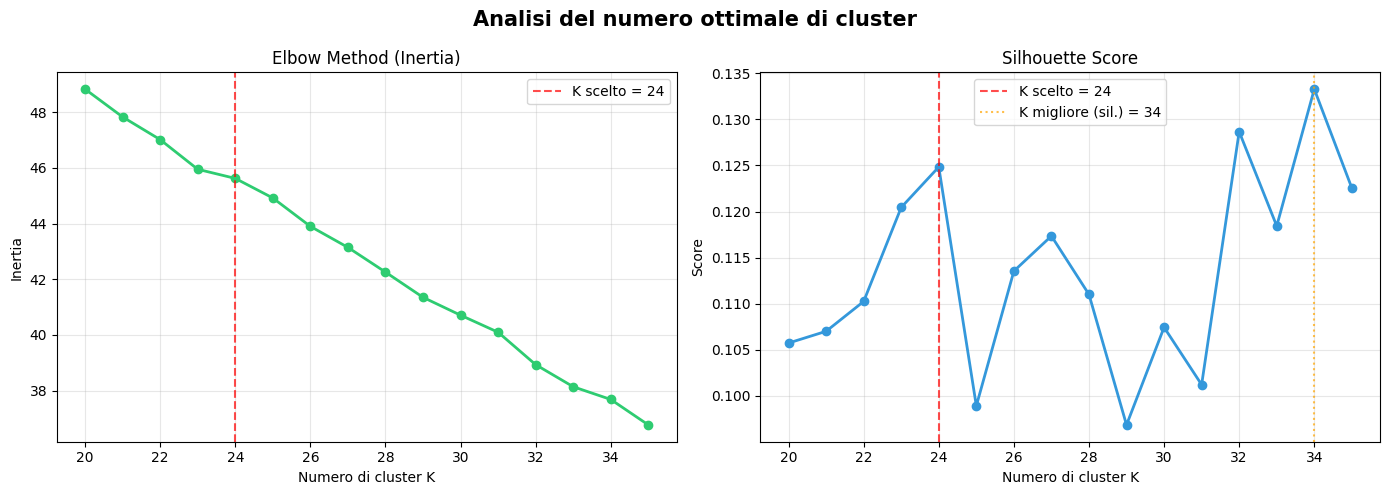


K con Silhouette massimo: 34 (score=0.1333)


In [12]:
# Ricerca del K ottimale
print(f"Test K-Means per K da {K_MIN} a {K_MAX}...\n")

k_range = range(K_MIN, K_MAX + 1)
inertie = []
silhouette_scores = []

for k in k_range:
    km  = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=15, max_iter=500)
    lbl = km.fit_predict(embeddings)
    inertie.append(km.inertia_)
    sil = silhouette_score(embeddings, lbl)
    silhouette_scores.append(sil)
    print(f"  K={k:2d} | Inertia={km.inertia_:8.1f} | Silhouette={sil:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Analisi del numero ottimale di cluster", fontsize=15, fontweight="bold")

ax1.plot(list(k_range), inertie, marker="o", color="#2ecc71", linewidth=2, markersize=6)
ax1.set_title("Elbow Method (Inertia)")
ax1.set_xlabel("Numero di cluster K")
ax1.set_ylabel("Inertia")
ax1.axvline(K_FINALE, color="red", linestyle="--", alpha=0.7, label=f"K scelto = {K_FINALE}")
ax1.legend()
ax1.grid(alpha=0.3)

best_k_sil = list(k_range)[int(np.argmax(silhouette_scores))]
ax2.plot(list(k_range), silhouette_scores, marker="o", color="#3498db", linewidth=2, markersize=6)
ax2.set_title("Silhouette Score")
ax2.set_xlabel("Numero di cluster K")
ax2.set_ylabel("Score")
ax2.axvline(K_FINALE,  color="red", linestyle="--", alpha=0.7, label=f"K scelto = {K_FINALE}")
ax2.axvline(best_k_sil, color="orange", linestyle=":",  alpha=0.7, label=f"K migliore (sil.) = {best_k_sil}")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()
print(f"\nK con Silhouette massimo: {best_k_sil} (score={max(silhouette_scores):.4f})")

In [13]:
# Clustering finale
# Aggiorniamo K_FINALE nella cella di configurazione dopo aver analizzato i grafici sopra, poi rieseguiamo da quella cella in poi.

km_finale = KMeans(n_clusters=K_FINALE, random_state=RANDOM_STATE, n_init=20, max_iter=1000)
labels = km_finale.fit_predict(embeddings)

sil_finale = silhouette_score(embeddings, labels)
print(f"K-Means eseguito con K={K_FINALE}.")
print(f"Silhouette Score finale: {sil_finale:.4f}.")

K-Means eseguito con K=24.
Silhouette Score finale: 0.1185.


In [14]:
# Mappatura sul dataframe
cat_to_cluster = {cat: int(labels[i]) for i, cat in enumerate(categorie)}
df['cluster_id'] = df[col_categoria].map(cat_to_cluster)

print("Colonna 'cluster_id' aggiunta al DataFrame.")
print(df['cluster_id'].value_counts().sort_index())

Colonna 'cluster_id' aggiunta al DataFrame.
cluster_id
0      151
1     1666
2     1102
3      181
4       53
5      368
6     1599
7      481
8      194
9      127
10     319
11     137
12     317
13    1357
14      26
15     222
16      93
17     117
18       9
19      33
20       1
21      50
22     659
23     143
Name: count, dtype: int64


In [15]:
# Ispezione manuale dei cluster
# Stampiamo ogni cluster con le sue categorie membro ordinate per frequenza decrescente. 
# Usiamo questo output per valutare la coerenza semantica e decidere se modificare K_FINALE prima di procedere al naming.

print("-" * 70)
print(f"Ispezione cluster (K={K_FINALE})")

for cluster_id in sorted(set(labels)):
    membri = [cat for cat, cid in sorted(cat_to_cluster.items(), key=lambda x: -frequenze_assolute.get(x[0], 0)) if cid == cluster_id]
    freq_tot = sum(frequenze_assolute.get(m, 0) for m in membri)
    perc_tot = freq_tot / frequenze_assolute.sum() * 100

    print(f"\nCluster {cluster_id:2d}  |  {len(membri)} categorie  |  {freq_tot} articoli ({perc_tot:.1f}%)")
    print("-" * 50)
    for m in membri:
        f = frequenze_assolute.get(m, 0)
        p = frequenze_percentuali.get(m, 0)
        print(f"  {f:5d} ({p:.2f}%)  {m}")

----------------------------------------------------------------------
Ispezione cluster (K=24)

Cluster  0  |  3 categorie  |  151 articoli (1.6%)
--------------------------------------------------
    120 (1.28%)  Cornici e immagini da parete
     26 (0.28%)  Mobili da lavabo
      5 (0.05%)  Mobili alti e scaffali per il bagno

Cluster  1  |  17 categorie  |  1666 articoli (17.7%)
--------------------------------------------------
   1027 (10.92%)  Fodere per divani e poltrone
    184 (1.96%)  Tende moderne e classiche
    152 (1.62%)  Pomelli e maniglie
     72 (0.77%)  Mensole e ganci
     68 (0.72%)  Cuscini e fodere per cuscini
     35 (0.37%)  Coltelli e taglieri
     27 (0.29%)  Cuscini e poggiatesta
     18 (0.19%)  Cavi e prese elettriche
     17 (0.18%)  Piatti da portata e vassoi
     15 (0.16%)  Ombrelloni e gazebo
     14 (0.15%)  Gambe per divani e poltrone
     14 (0.15%)  Gambe e Piedi per letti
     10 (0.11%)  Vasi e ciotole
      5 (0.05%)  Bacheche e Lavagne
     

Calcolo proiezione t-SNE...


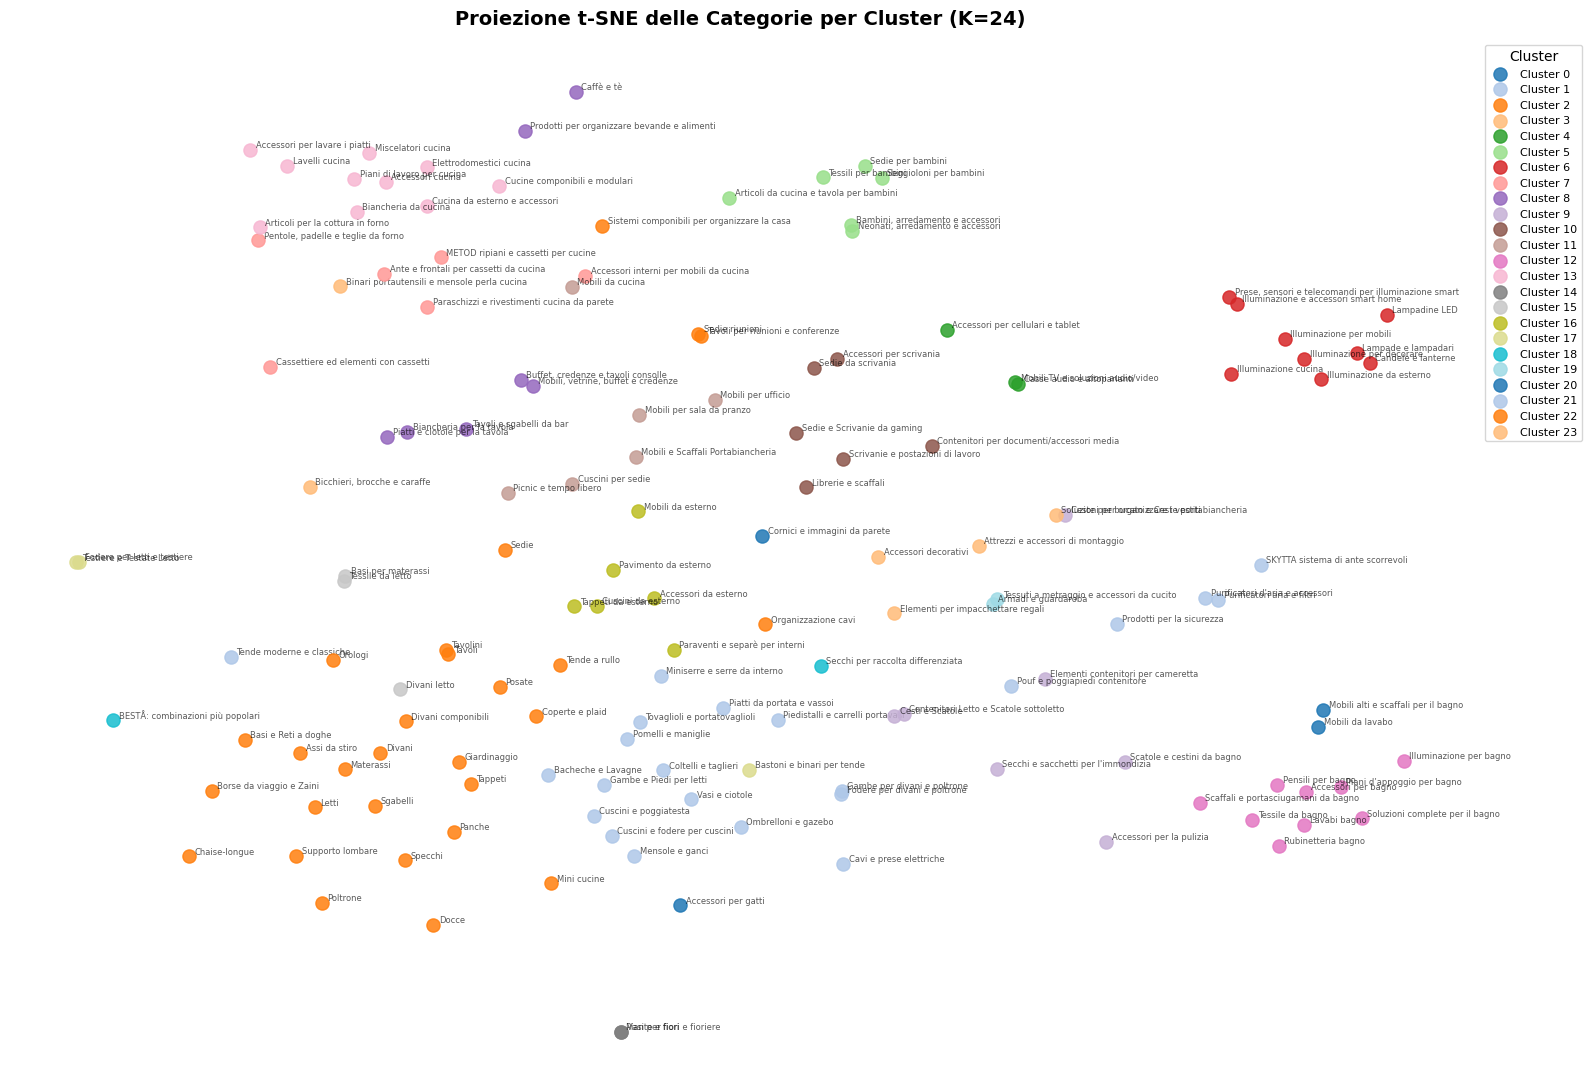

In [16]:
# Visualizzazione t-SNE
print("Calcolo proiezione t-SNE...")
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=min(30, len(categorie) - 1))
coords = tsne.fit_transform(embeddings)
palette = sns.color_palette("tab20", n_colors=K_FINALE)

fig, ax = plt.subplots(figsize=(16, 11))

for cluster_id in sorted(set(labels)):
    mask = labels == cluster_id
    xs, ys = coords[mask, 0], coords[mask, 1]
    ax.scatter(xs, ys, color=palette[cluster_id % len(palette)], s=90, alpha=0.85, label=f"Cluster {cluster_id}", zorder=3)
    for x, y, cat in zip(xs, ys, np.array(categorie)[mask]):
        ax.annotate(cat, (x, y), fontsize=6, alpha=0.65, xytext=(4, 2), textcoords="offset points")

ax.set_title(f"Proiezione t-SNE delle Categorie per Cluster (K={K_FINALE})", fontsize=14, fontweight="bold", pad=15)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=8, title="Cluster")
ax.axis("off")
plt.tight_layout()
plt.show()

-> **Approccio 2. clustering gerarchico agglomerativo con Ward Linkage**

Dato il precedente fallimento con il K-Means, si decide di testare il clustering gerarchico agglomerativo con Ward linkage. A differenza di K-Means, questo approccio non assume una forma sferica dei cluster e costruisce la soluzione in modo bottom-up: ogni categoria parte come cluster a sé, e i gruppi vengono fusi iterativamente minimizzando l'aumento di varianza interna ad ogni passo. Il risultato viene visualizzato tramite un dendrogramma, che permette di leggere visivamente la struttura gerarchica dei dati e di scegliere il numero di cluster in modo motivato, identificando il livello di distanza al quale i rami si fondono in modo più naturale.

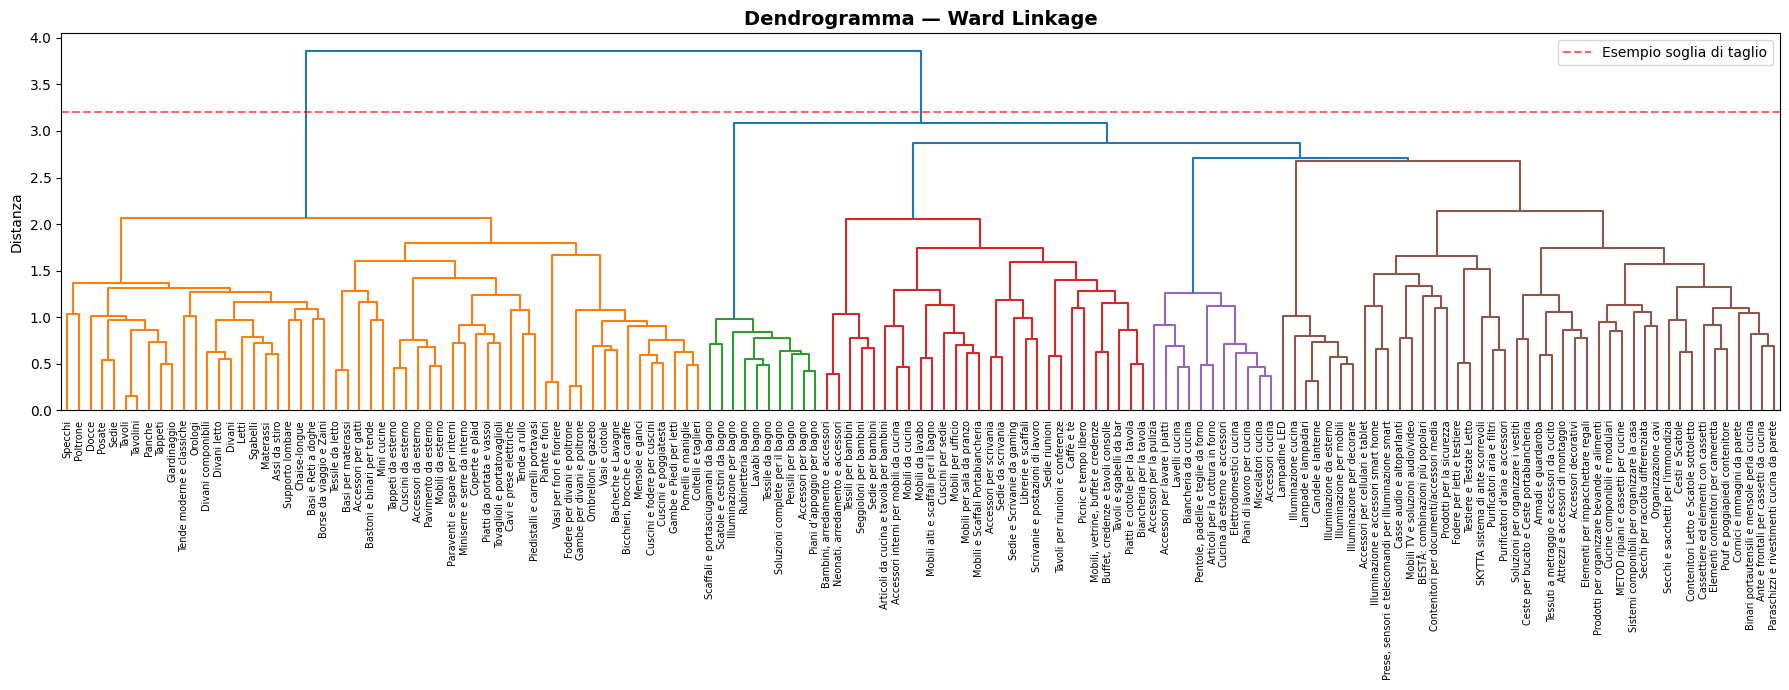

In [17]:
# Clustering Gerarchico (Ward)
# Dendrogramma (utile per capire visivamente dove tagliare)
fig, ax = plt.subplots(figsize=(18, 7))
Z = linkage(embeddings, method='ward')
dendrogram(Z, labels=categorie, leaf_rotation=90, leaf_font_size=7, ax=ax)
ax.set_title("Dendrogramma — Ward Linkage", fontsize=14, fontweight="bold")
ax.set_ylabel("Distanza")
ax.axhline(y=3.2, color='red', linestyle='--', alpha=0.6, label="Esempio soglia di taglio")
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# Clustering finale con Ward
K_WARD = 22  

ward = AgglomerativeClustering(n_clusters=K_WARD, metric='euclidean', linkage='ward')
labels_ward = ward.fit_predict(embeddings)

sil_ward = silhouette_score(embeddings, labels_ward)
print(f"AgglomerativeClustering Ward — K={K_WARD}")
print(f"Silhouette Score: {sil_ward:.4f}")

# Mappatura sul DataFrame
cat_to_cluster_ward = {cat: int(labels_ward[i]) for i, cat in enumerate(categorie)}
df['cluster_id'] = df[col_categoria].map(cat_to_cluster_ward)

AgglomerativeClustering Ward — K=22
Silhouette Score: 0.1303


In [19]:
# Ispezione manuale cluster Ward
print("-" * 70)
print(f"Ispezione cluster Ward  (K={K_WARD})")

for cluster_id in sorted(set(labels_ward)):
    membri = [cat for cat, cid in sorted(cat_to_cluster_ward.items(),key=lambda x: -frequenze_assolute.get(x[0], 0)) if cid == cluster_id]
    freq_tot = sum(frequenze_assolute.get(m, 0) for m in membri)
    perc_tot = freq_tot / frequenze_assolute.sum() * 100

    print(f"\nCluster {cluster_id:2d}  |  {len(membri)} categorie  |  {freq_tot} articoli ({perc_tot:.1f}%)")
    print("-" * 50)
    for m in membri:
        f = frequenze_assolute.get(m, 0)
        p = frequenze_percentuali.get(m, 0)
        print(f"  {f:5d} ({p:.2f}%)  {m}")

----------------------------------------------------------------------
Ispezione cluster Ward  (K=22)

Cluster  0  |  5 categorie  |  77 articoli (0.8%)
--------------------------------------------------
     34 (0.36%)  Casse audio e altoparlanti
     25 (0.27%)  Contenitori per documenti/accessori media
      8 (0.09%)  Prodotti per la sicurezza
      5 (0.05%)  Mobili TV e soluzioni audio/video
      5 (0.05%)  BESTÅ: combinazioni più popolari

Cluster  1  |  10 categorie  |  499 articoli (5.3%)
--------------------------------------------------
    135 (1.44%)  Binari portautensili e mensole perla cucina
    120 (1.28%)  Cornici e immagini da parete
     66 (0.70%)  Cesti e Scatole
     50 (0.53%)  Ante e frontali per cassetti da cucina
     49 (0.52%)  Cassettiere ed elementi con cassetti
     30 (0.32%)  Elementi contenitori per cameretta
     25 (0.27%)  Pouf e poggiapiedi contenitore
     17 (0.18%)  Contenitori Letto e Scatole sottoletto
      4 (0.04%)  Paraschizzi e rivestim

-> **Approccio 3: raggruppamento tramite LLM**

Il clustering geometrico (K-Means e Ward) ha mostrato limiti strutturali difficili da superare: con 147 punti in uno spazio di embedding a 384 dimensioni, gli algoritmi di distanza faticano a separare categorie semanticamente distanti ma lessicalmente simili, e tendono a produrre cluster residuali eterogenei che raccolgono tutto ciò che non rientra nei gruppi più densi. Si adotta quindi un approccio diverso: il raggruppamento viene delegato direttamente a un LLM (`Gemini 3.1. Flash Lite`), che riceve l'elenco completo delle 147 categorie e produce un mapping verso un numero ridotto di macro-categorie. Il modello sfrutta la comprensione semantica del linguaggio naturale anziché la geometria dello spazio vettoriale, risultando più adatto a un catalogo in cui le etichette sono descrittive. Il risultato viene restituito come JSON e mappato direttamente sul DataFrame.

In [ ]:
API_KEY = '[secret]'
genai.configure(api_key=API_KEY)

#  Verifica modelli disponibili
print("Modelli disponibili:\n")
for m in genai.list_models():
    if 'generateContent' in m.supported_generation_methods:
        print(f"  {m.name}")

Modelli disponibili:

  models/gemini-2.5-flash
  models/gemini-2.5-pro
  models/gemini-2.0-flash
  models/gemini-2.0-flash-001
  models/gemini-2.0-flash-lite-001
  models/gemini-2.0-flash-lite
  models/gemini-2.5-flash-preview-tts
  models/gemini-2.5-pro-preview-tts
  models/gemma-4-26b-a4b-it
  models/gemma-4-31b-it
  models/gemini-flash-latest
  models/gemini-flash-lite-latest
  models/gemini-pro-latest
  models/gemini-2.5-flash-lite
  models/gemini-2.5-flash-image
  models/gemini-3-pro-preview
  models/gemini-3-flash-preview
  models/gemini-3.1-pro-preview
  models/gemini-3.1-pro-preview-customtools
  models/gemini-3.1-flash-lite-preview
  models/gemini-3.1-flash-lite
  models/gemini-3-pro-image-preview
  models/gemini-3-pro-image
  models/nano-banana-pro-preview
  models/gemini-3.1-flash-image-preview
  models/gemini-3.1-flash-image
  models/gemini-3.5-flash
  models/lyria-3-clip-preview
  models/lyria-3-pro-preview
  models/gemini-3.1-flash-tts-preview
  models/gemini-robotics-er

In [ ]:
genai.configure(api_key="[secret]")
model_llm = genai.GenerativeModel("models/gemini-3.1-flash-lite")

categorie_list = frequenze_assolute.index.tolist()

prompt = f"""Sei un esperto di e-commerce e retail di arredamento e prodotti per la casa.
Ti fornisco l'elenco completo di {len(categorie_list)} categorie di prodotti provenienti da un catalogo.
Il tuo compito è raggrupparle in macro-categorie logiche e coerenti (dalle 25-35 macro-categorie), che scegli tu, con nomi brevi e chiari in italiano.
Regole:
- Ogni categoria deve essere assegnata a esattamente una macro-categoria.
- Le macro-categorie devono essere commercialmente significative e mutuamente esclusive.
- Tieni conto che alcune etichette contengono nomi di serie dell'azienda (METOD, BESTÅ, SKYTTA): raggruppale per funzione, non per nome di serie-
- Non creare macro-categorie con una sola categoria al loro interno, accorpale alla più affine.
Rispondi SOLO con un oggetto JSON valido, senza testo aggiuntivo, senza backtick, nel formato:
{{"categoria originale": "macro-categoria", ...}}

Categorie:
{json.dumps(categorie_list, ensure_ascii=False, indent=2)}
"""

response = model_llm.generate_content(prompt)
raw = response.text.strip()

# Pulizia robusta nel caso il modello aggiunga backtick o prefissi
if raw.startswith("```"):
    raw = raw.split("```")[1]
    if raw.startswith("json"):
        raw = raw[4:]
raw = raw.strip()

mapping = json.loads(raw)

# Verifica copertura
non_mappate = [c for c in categorie_list if c not in mapping]
if non_mappate:
    print(f"Attenzione: {len(non_mappate)} categorie non mappate:")
    for c in non_mappate:
        print(f"  - {c}")
else:
    print(f"Tutte le {len(categorie_list)} categorie mappate correttamente.")

macro_uniche = sorted(set(mapping.values()))
print(f"Macro-categorie generate: {len(macro_uniche)}")
for m in macro_uniche:
    print(f"  - {m}")

Tutte le 147 categorie mappate correttamente.
Macro-categorie generate: 22
  - Accessori personali
  - Bagno
  - Casa e pulizia
  - Complementi d'arredo
  - Cucina e tavola
  - Cucine e accessori
  - Decorazioni
  - Ferramenta e accessori mobili
  - Giardinaggio
  - Illuminazione
  - Letti e materassi
  - Mobili da esterno
  - Mobili per bambini
  - Mobili per il soggiorno
  - Mobili per la camera da letto
  - Mobili per la zona pranzo
  - Mobili per ufficio
  - Sedute
  - Sistemi di archiviazione
  - Smart Home
  - Tende e tendaggi
  - Tessili per la casa


In [34]:
# Mappatura sul DataFrame e distribuzione
df['macro_categoria'] = df[col_categoria].map(mapping)

# Ispezione: per ogni macro-categoria, le categorie originali che contiene
print("Ispezione Macro-Categorie (LLM)")

for macro in sorted(set(mapping.values())):
    membri = [c for c, m in mapping.items() if m == macro]
    membri_ordinati = sorted(membri, key=lambda x: -frequenze_assolute.get(x, 0))
    freq_tot = sum(frequenze_assolute.get(m, 0) for m in membri)
    perc_tot = freq_tot / frequenze_assolute.sum() * 100

    print(f"\n[{macro}]  —  {len(membri)} categorie  |  {freq_tot} articoli ({perc_tot:.1f}%)")
    print("-" * 50)
    for m in membri_ordinati:
        f = frequenze_assolute.get(m, 0)
        p = frequenze_percentuali.get(m, 0)
        print(f"  {f:5d} ({p:.2f}%)  {m}")

Ispezione Macro-Categorie (LLM)

[Accessori personali]  —  2 categorie  |  9 articoli (0.1%)
--------------------------------------------------
      7 (0.07%)  Borse da viaggio e Zaini
      2 (0.02%)  Picnic e tempo libero

[Bagno]  —  12 categorie  |  323 articoli (3.4%)
--------------------------------------------------
     81 (0.86%)  Accessori per bagno
     47 (0.50%)  Docce
     42 (0.45%)  Lavabi bagno
     40 (0.43%)  Scaffali e portasciugamani da bagno
     39 (0.41%)  Soluzioni complete per il bagno
     26 (0.28%)  Mobili da lavabo
     21 (0.22%)  Rubinetteria bagno
     12 (0.13%)  Mobili e Scaffali Portabiancheria
      5 (0.05%)  Piani d’appoggio per bagno
      5 (0.05%)  Mobili alti e scaffali per il bagno
      4 (0.04%)  Scatole e cestini da bagno
      1 (0.01%)  Pensili per bagno

[Casa e pulizia]  —  5 categorie  |  15 articoli (0.2%)
--------------------------------------------------
      5 (0.05%)  Accessori per la pulizia
      4 (0.04%)  Secchi per raccolt

-> **Approccio finale ibrido: classificazione manuale interattiva**

I risultati ottenuti tramite i due approcci di clustering geometrico e il successivo tentativo di raggruppamento automatico tramite LLM hanno prodotto risultati parzialmente soddisfacenti: se da un lato alcuni macro-gruppi tematici emergevano con coerenza (illuminazione, bagno, bambini, cucina), dall'altro persistevano cluster residuali eterogenei in cui categorie semanticamente distanti venivano aggregate per ragioni puramente geometriche o lessicali, senza una logica commerciale riconoscibile. Si è scelto pertanto di adottare un approccio ibrido: il mapping generato dall'LLM viene utilizzato come punto di partenza, ma la classificazione finale è affidata a una revisione manuale categoria per categoria. 

In [ ]:
# Classificazione manuale interattiva
# Lista categorie ordinate per frequenza decrescente
categorie_da_classificare = frequenze_assolute.index.tolist()

# Dizionario risultato (viene pre-popolato con il mapping LLM come punto di partenza)
mapping_manuale = dict(mapping) 
stato = {"i": 0}

# Widget
output       = widgets.Output()
label_cat    = widgets.HTML()
label_prog   = widgets.HTML()
label_freq   = widgets.HTML()

# Dropdown con le macro-categorie esistenti + possibilità di crearne una nuova
dropdown = widgets.Combobox(placeholder="Scegli o scrivi una macro-categoria...",options=sorted(set(mapping_manuale.values())),ensure_option=False,layout=widgets.Layout(width="400px"))
btn_conferma = widgets.Button(description="Conferma ✓", button_style="success")
btn_back     = widgets.Button(description="← Indietro", button_style="warning")
btn_salta    = widgets.Button(description="Salta →", button_style="info")

def aggiorna_vista():
    i = stato["i"]
    if i >= len(categorie_da_classificare):
        with output:
            clear_output()
            print("✅ Classificazione completata!")
        return

    cat = categorie_da_classificare[i]
    freq = frequenze_assolute.get(cat, 0)
    perc = frequenze_percentuali.get(cat, 0)
    assegnata = mapping_manuale.get(cat, "")

    label_prog.value = f"<b style='color:gray'>Categoria {i+1} di {len(categorie_da_classificare)}</b>"
    label_cat.value  = f"<h3 style='color:#1a1a2e; margin:4px 0'>{cat}</h3>"
    label_freq.value = f"<span style='color:gray'>{freq} articoli ({perc:.2f}%)</span>"
    dropdown.options = sorted(set(mapping_manuale.values()))
    dropdown.value = assegnata 

def on_conferma(b):
    i   = stato["i"]
    cat = categorie_da_classificare[i]
    val = dropdown.value.strip()
    if not val:
        with output:
            clear_output()
            print("⚠️ Inserisci una macro-categoria prima di confermare.")
        return
    mapping_manuale[cat] = val
    stato["i"] = min(i + 1, len(categorie_da_classificare))
    aggiorna_vista()

def on_back(b):
    stato["i"] = max(stato["i"] - 1, 0)
    aggiorna_vista()

def on_salta(b):
    stato["i"] = min(stato["i"] + 1, len(categorie_da_classificare))
    aggiorna_vista()

btn_conferma.on_click(on_conferma)
btn_back.on_click(on_back)
btn_salta.on_click(on_salta)

ui = widgets.VBox([label_prog,label_cat,label_freq,dropdown,widgets.HBox([btn_back, btn_conferma, btn_salta]),output])
display(ui)
aggiorna_vista()

In [37]:
# Applicazione del mapping manuale al dataframe (da eseguire solo dopo aver completato la classificazione sopra)
non_classificate = [c for c in categorie_da_classificare if c not in mapping_manuale]
if non_classificate:
    print(f"Attenzione: {len(non_classificate)} categorie ancora senza macro-categoria:")
    for c in non_classificate:
        print(f"  - {c}")
else:
    df['macro_categoria'] = df[col_categoria].map(mapping_manuale)
    macro_uniche = sorted(set(mapping_manuale.values()))
    print(f"Mapping applicato. Macro-categorie totali: {len(macro_uniche)}.")
    for m in macro_uniche:
        n = sum(1 for v in mapping_manuale.values() if v == m)
        print(f"  {m}  ({n} categorie originali)")

Mapping applicato. Macro-categorie totali: 22.
  Articoli per la tavola e la cucina  (11 categorie originali)
  Contenitori e scatole  (6 categorie originali)
  Decorazioni  (11 categorie originali)
  Divani, poltrone e accessori  (8 categorie originali)
  Elettrodomestici  (1 categorie originali)
  Elettronica  (4 categorie originali)
  Ferramenta e accessori mobili  (4 categorie originali)
  Illuminazione  (7 categorie originali)
  Illuminazione Smart Home  (2 categorie originali)
  Letti e materassi  (6 categorie originali)
  Miscelatori e rubinetteria  (2 categorie originali)
  Mobili e accessori da esterno  (7 categorie originali)
  Mobili e accessori per bambini e neonati  (7 categorie originali)
  Mobili e accessori per il bagno  (10 categorie originali)
  Mobili e accessori per la cucina  (11 categorie originali)
  Mobili e accessori per ufficio  (6 categorie originali)
  Mobili per organizzare la casa  (11 categorie originali)
  Pulizia e Altro  (10 categorie originali)
  Tapp

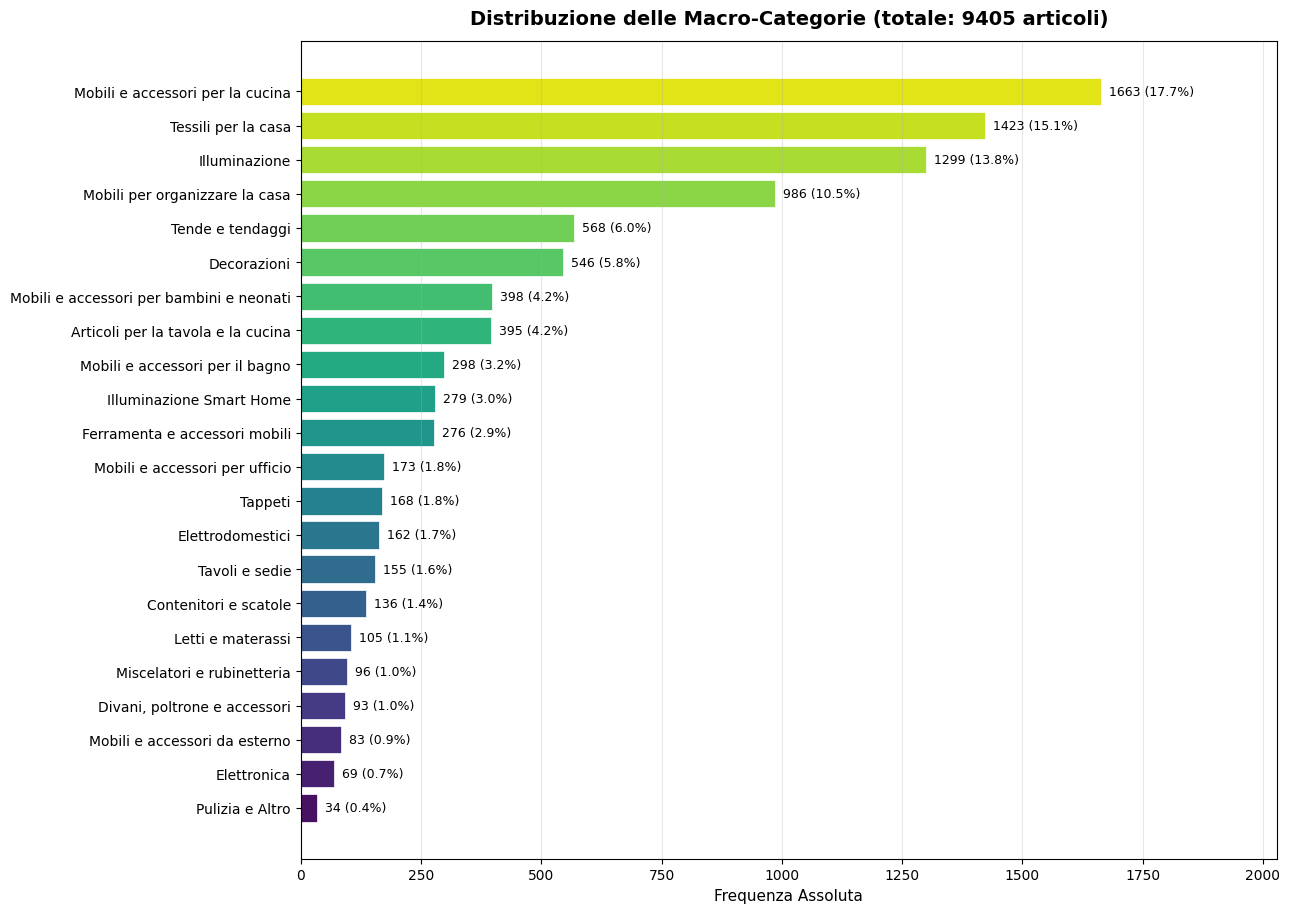

In [39]:
# Panoramica: Distribuzione delle macro-categorie
freq_macro = df['macro_categoria'].value_counts().sort_values()
perc_macro = df['macro_categoria'].value_counts(normalize=True).sort_values() * 100
n_macro  = len(freq_macro)

palette  = sns.color_palette("viridis", n_colors=n_macro)
fig, ax = plt.subplots(figsize=(13, max(6, n_macro * 0.42)))
bars = ax.barh(freq_macro.index, freq_macro.values, color=palette, edgecolor="white", linewidth=0.5)

for bar, val, pct in zip(bars, freq_macro.values, perc_macro[freq_macro.index].values):
    ax.text(val + freq_macro.max() * 0.01, bar.get_y() + bar.get_height() / 2, f"{val} ({pct:.1f}%)", va="center", ha="left", fontsize=9)

ax.set_xlim(0, freq_macro.max() * 1.22)
ax.set_xlabel("Frequenza Assoluta", fontsize=11)
ax.set_title(f"Distribuzione delle Macro-Categorie (totale: {df.shape[0]} articoli)", fontsize=14, fontweight="bold", pad=12)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
# Più nel dettaglio: sottocategorie originali per ogni macro-categoria
# Costruzione di un unico DataFrame gerarchico
dati_gerarchici = []
totale_assoluto = df.shape[0]
macro_ordinate = df['macro_categoria'].value_counts().index.tolist()  # ordine per frequenza decrescente

for macro in macro_ordinate:
    # Identifica le sottocategorie per questa macro
    sottocategorie = [c for c, m in mapping_manuale.items() if m == macro]
    # Calcola la frequenza totale della singola macro-categoria
    freq_tot_macro = sum(frequenze_assolute.get(c, 0) for c in sottocategorie)
    
    for sub in sottocategorie:
        freq = frequenze_assolute.get(sub, 0)
        if freq > 0:
            # Calcolo percentuali troncate per difetto
            pct_loc = math.floor((freq / freq_tot_macro) * 100) if freq_tot_macro > 0 else 0
            pct_glo = math.floor((freq / totale_assoluto) * 100) if totale_assoluto > 0 else 0
            
            dati_gerarchici.append({"Macro-Categoria": macro,"Sottocategoria": sub,"Frequenza": freq,"Incidenza su Macro": f"{pct_loc}%","Incidenza Totale": f"{pct_glo}%"})

df_viz = pd.DataFrame(dati_gerarchici)

# Grafico Sunburst
fig_sun = px.sunburst(df_viz,path=['Macro-Categoria', 'Sottocategoria'], values='Frequenza',color='Macro-Categoria',hover_data=['Incidenza su Macro', 'Incidenza Totale'],title='<b>Distribuzione Articoli: Macro vs Sottocategorie</b>',color_discrete_sequence=px.colors.qualitative.Alphabet)
fig_sun.update_traces(textinfo="label+value")
fig_sun.update_layout(width=900, height=900, margin=dict(t=50, l=0, r=0, b=0))
fig_sun.show()


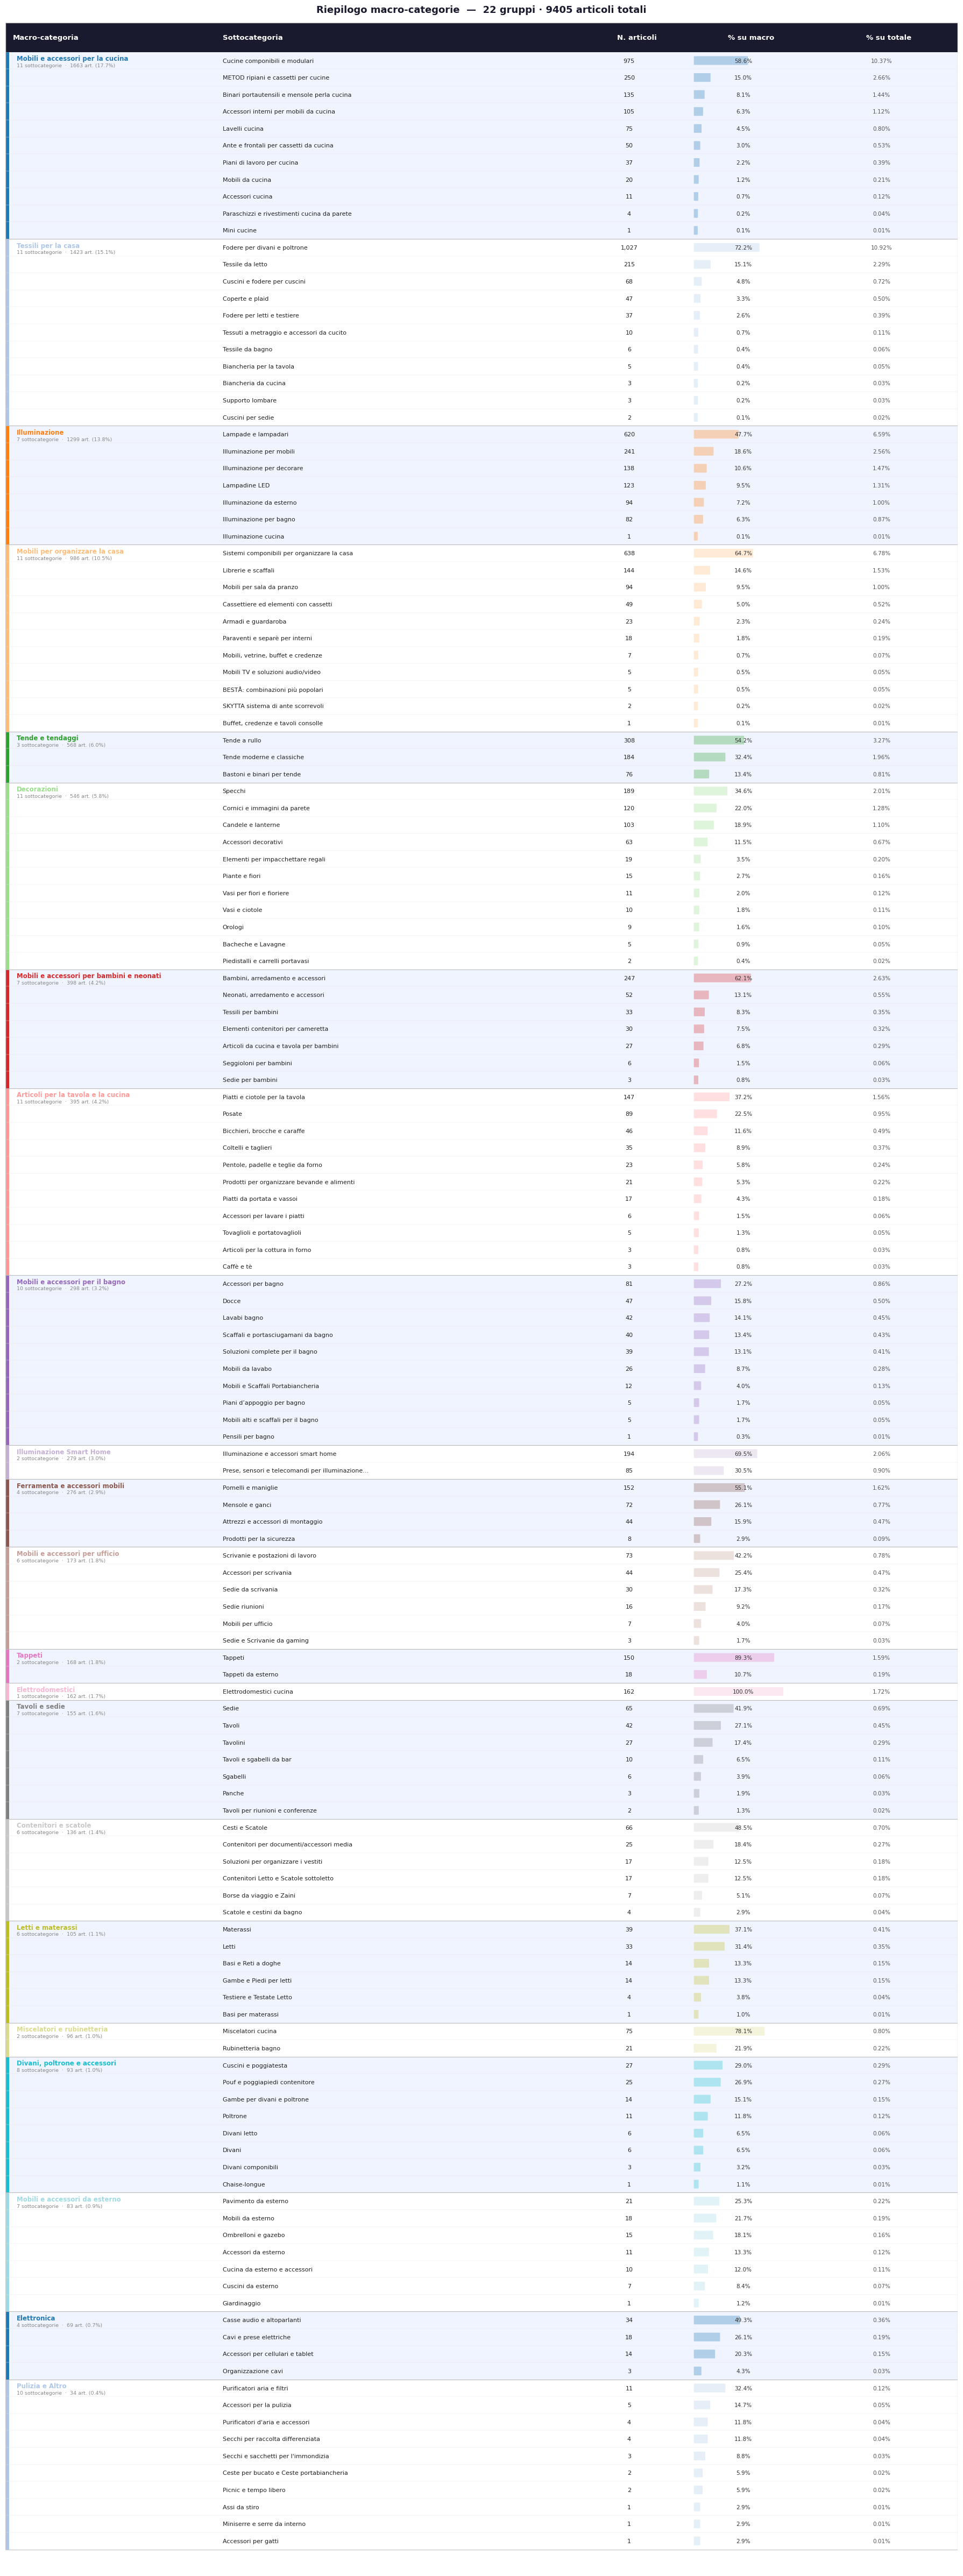

In [58]:
# Tabella riepilogativa
macro_ordinate  = df['macro_categoria'].value_counts().index.tolist()
n_macro = len(macro_ordinate)
palette_macro   = sns.color_palette("tab20", n_colors=n_macro)
totale_articoli = df.shape[0]

righe_tabella = []
for idx, macro in enumerate(macro_ordinate):
    sotto_freq = {c: frequenze_assolute.get(c, 0) for c, m in mapping_manuale.items() if m == macro}
    sotto_ord = sorted(sotto_freq.items(), key=lambda x: -x[1])
    freq_tot  = sum(sotto_freq.values())
    perc_tot  = freq_tot / totale_articoli * 100

    for rank, (cat, freq) in enumerate(sotto_ord):
        perc_cat  = freq / totale_articoli * 100
        perc_macro = freq / freq_tot * 100 if freq_tot > 0 else 0
        righe_tabella.append({"macro": macro, "macro_idx": idx, "prima_riga": rank == 0, "n_sotto": len(sotto_ord), "freq_tot": freq_tot, 
                              "perc_tot": perc_tot, "categoria": cat, "freq": freq, "perc_cat": perc_cat, "perc_macro": perc_macro,})
n_righe = len(righe_tabella)

# Layout
COL_X = [0.00, 0.22, 0.60, 0.72, 0.84]   # x di inizio colonna (0-1)
COL_W = [0.21, 0.37, 0.11, 0.11, 0.16]   # larghezza colonna
HEADERS  = ["Macro-categoria", "Sottocategoria", "N. articoli", "% su macro", "% su totale"]
ROW_H = 0.32   # altezza riga in pollici
HEAD_H = 0.55   # altezza header

fig_h = HEAD_H + n_righe * ROW_H + 0.4
fig, ax = plt.subplots(figsize=(18, fig_h))
ax.set_xlim(0, 1)
ax.set_ylim(0, fig_h)
ax.axis("off")

# Header
ax.add_patch(FancyBboxPatch((0, fig_h - HEAD_H), 1, HEAD_H, boxstyle="square,pad=0", facecolor="#1a1a2e", edgecolor="none", zorder=2))
for col, (x, w, label) in enumerate(zip(COL_X, COL_W, HEADERS)):
    ha = "left" if col < 2 else "center"
    ax.text(x + (0 if col < 2 else w / 2) + 0.008, fig_h - HEAD_H / 2, label, ha=ha, va="center", fontsize=9.5, fontweight="bold", color="white", zorder=3)

# Righe
y_cursor = fig_h - HEAD_H  # partiamo subito sotto l'header

for r in righe_tabella:
    y_top = y_cursor - ROW_H
    color_macro = palette_macro[r["macro_idx"] % n_macro]
    
    # Sfondo alternato per macro (blocchi colorati leggeri)
    bg_color = "#f0f4ff" if r["macro_idx"] % 2 == 0 else "#ffffff"
    ax.add_patch(FancyBboxPatch((0, y_top), 1, ROW_H, boxstyle="square,pad=0", facecolor=bg_color, edgecolor="none", zorder=0))

    # Bordo colorato a sinistra per la macro
    ax.add_patch(FancyBboxPatch((0, y_top), 0.004, ROW_H, boxstyle="square,pad=0", facecolor=color_macro, edgecolor="none", zorder=1))

    # Col 0: nome macro (solo sulla prima riga del gruppo)
    if r["prima_riga"]:
        ax.text(0.012, y_top + ROW_H * 0.62, r["macro"], ha="left", va="center", fontsize=8.5, fontweight="bold", color=color_macro, zorder=2)
        ax.text(0.012, y_top + ROW_H * 0.22, f"{r['n_sotto']} sottocategorie  ·  {r['freq_tot']} art. ({r['perc_tot']:.1f}%)", ha="left", va="center", fontsize=6.8, color="#888888", zorder=2)

    # Col 1: nome sottocategoria 
    nome = r["categoria"] if len(r["categoria"]) <= 48 else r["categoria"][:46] + "…"
    ax.text(COL_X[1] + 0.008, y_top + ROW_H / 2, nome, ha="left", va="center", fontsize=8, color="#222222", zorder=2)

    # Col 2: frequenza assoluta 
    ax.text(COL_X[2] + COL_W[2] / 2, y_top + ROW_H / 2, f"{r['freq']:,}", ha="center", va="center", fontsize=8, color="#222222", zorder=2)

    # Col 3: % su macro (con mini barra)
    bar_max_w = COL_W[3] - 0.02
    bar_w = bar_max_w * r["perc_macro"] / 100
    ax.add_patch(FancyBboxPatch((COL_X[3] + 0.005, y_top + ROW_H * 0.25), bar_w, ROW_H * 0.50, boxstyle="round,pad=0.002", facecolor=color_macro, alpha=0.30, edgecolor="none", zorder=1))
    ax.text(COL_X[3] + COL_W[3] / 2, y_top + ROW_H / 2, f"{r['perc_macro']:.1f}%", ha="center", va="center", fontsize=7.5, color="#333333", zorder=2)

    # Col 4: % su totale
    ax.text(COL_X[4] + COL_W[4] / 2, y_top + ROW_H / 2, f"{r['perc_cat']:.2f}%", ha="center", va="center", fontsize=7.5, color="#555555", zorder=2)

    # Linea separatrice
    lw = 0.8 if r["prima_riga"] and r["macro_idx"] > 0 else 0.3
    lcolor = "#bbbbbb" if r["prima_riga"] and r["macro_idx"] > 0 else "#e5e5e5"
    ax.axhline(y_cursor, color=lcolor, linewidth=lw, zorder=1)

    y_cursor -= ROW_H

# Bordo esterno
ax.add_patch(FancyBboxPatch((0, y_cursor), 1, fig_h - y_cursor, boxstyle="square,pad=0", facecolor="none", edgecolor="#cccccc", linewidth=1, zorder=4))

ax.set_title(f"Riepilogo macro-categorie  —  {n_macro} gruppi · {totale_articoli} articoli totali", fontsize=13, fontweight="bold", pad=14, color="#1a1a2e")
plt.tight_layout()
plt.savefig("tabella_macro_categorie.png", dpi=180, bbox_inches="tight")
plt.show()

## **Conclusioni e Salvataggio**

In [60]:
df.columns

Index(['ID Prodotto', 'Numero Articolo Catalogo', 'Descrizione Completa',
       'Cura', 'Buono a sapersi + Sicurezza e conformità', 'Disponibilità',
       'Condizione Usato', 'Motivo Vendita', 'Nota Classificata',
       'Imballaggio Presente', 'Prezzo Originale', 'Prezzo Scontato', 'Sconto',
       'Nome Negozio', 'Tipologia Negozio', 'Designer Nome',
       'Riciclato_componenti', 'Classe efficienza energetica',
       'Classe efficienza energetica cavita',
       'Consumo energetico annuo (kWh/anno)', 'Flusso luminoso nominale (lm)',
       'Portata max 3 bar (l/min)', 'Efficienza fluidodinamica (%)',
       'Misure Standardizzata', 'Categoria Principale', 'cluster_id',
       'macro_categoria'],
      dtype='str')

In [ ]:
# Pulizia e rinomina colonne
df = df.drop(columns=['Categoria Principale', 'cluster_id'])
df = df.rename(columns={'macro_categoria': 'Categoria Prodotto'})

print(f"Colonne finali del DataFrame: {df.shape[1]}.")
print(df.columns.tolist())

Colonne finali del DataFrame: 25.
['ID Prodotto', 'Numero Articolo Catalogo', 'Descrizione Completa', 'Cura', 'Buono a sapersi + Sicurezza e conformità', 'Disponibilità', 'Condizione Usato', 'Motivo Vendita', 'Nota Classificata', 'Imballaggio Presente', 'Prezzo Originale', 'Prezzo Scontato', 'Sconto', 'Nome Negozio', 'Tipologia Negozio', 'Designer Nome', 'Riciclato_componenti', 'Classe efficienza energetica', 'Classe efficienza energetica cavita', 'Consumo energetico annuo (kWh/anno)', 'Flusso luminoso nominale (lm)', 'Portata max 3 bar (l/min)', 'Efficienza fluidodinamica (%)', 'Misure Standardizzata', 'Categoria Prodotto']


In [62]:
df = df.rename(columns={'Riciclato_componenti' : 'Componenti Riciclate'})

ordine_colonne = [ 'ID Prodotto', 'Numero Articolo Catalogo', 'Categoria Prodotto', 'Descrizione Completa', 'Cura', 'Buono a sapersi + Sicurezza e conformità', 'Disponibilità', 
                  'Condizione Usato', 'Motivo Vendita', 'Nota Classificata', 'Imballaggio Presente', 'Prezzo Originale', 'Prezzo Scontato', 'Sconto', 
                  'Nome Negozio', 'Tipologia Negozio', 'Designer Nome', 'Classe efficienza energetica', 'Classe efficienza energetica cavita', 
                  'Consumo energetico annuo (kWh/anno)', 'Flusso luminoso nominale (lm)', 'Portata max 3 bar (l/min)', 'Efficienza fluidodinamica (%)', 
                  'Componenti Riciclate', 'Misure Standardizzata']

df = df[ordine_colonne]

In [64]:
# Colonne
nomi_colonne = list(df.columns)
num_colonne_visive = 3
num_righe = math.ceil(len(nomi_colonne) / num_colonne_visive)

html_colonne = "<table style='width:100%; border:none; text-align:left;'>"
for r in range(num_righe):
    html_colonne += "<tr>"
    for c in range(num_colonne_visive):
        idx = c * num_righe + r
        if idx < len(nomi_colonne):
            num = idx + 1
            html_colonne += f"<td style='padding:4px 8px;'><code>{num}. {nomi_colonne[idx]}</code></td>"
        else:
            html_colonne += "<td></td>"
    html_colonne += "</tr>"
html_colonne += "</table>"

display(HTML(html_colonne))

# Salvataggio file
cartella_destinazione = os.path.join("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
if not os.path.exists(cartella_destinazione):
    os.makedirs(cartella_destinazione)
    
nome_file = "3_riduzione_categorie__usato.csv"
percorso_salvataggio = os.path.join(cartella_destinazione, nome_file)
df.to_csv(percorso_salvataggio, index=False)

display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
display(HTML(f"""<h4><b>Salvataggio completato</b>:</h4> <ul>
             <li>Il dataset è stato salvato con successo in: <b>{percorso_salvataggio}</b>.</li>
             <li>Righe: <b>{df.shape[0]:,}</b>. Colonne: <b>{df.shape[1]}</b>.</li></ul>"""))

1. ID Prodotto,10. Nota Classificata,19. Classe efficienza energetica cavita
2. Numero Articolo Catalogo,11. Imballaggio Presente,20. Consumo energetico annuo (kWh/anno)
3. Categoria Prodotto,12. Prezzo Originale,21. Flusso luminoso nominale (lm)
4. Descrizione Completa,13. Prezzo Scontato,22. Portata max 3 bar (l/min)
5. Cura,14. Sconto,23. Efficienza fluidodinamica (%)
6. Buono a sapersi + Sicurezza e conformità,15. Nome Negozio,24. Componenti Riciclate
7. Disponibilità,16. Tipologia Negozio,25. Misure Standardizzata
8. Condizione Usato,17. Designer Nome,
9. Motivo Vendita,18. Classe efficienza energetica,
